<a href="https://colab.research.google.com/github/caroline-reges/Image-Identification-Using-Deep-Learning/blob/main/Deep%20Learning%20Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import packages

In [1]:
#keeps google colab connected to my drive
from google.colab import drive
drive.mount('/content/drive')

import os #use to navigate folders

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files #used for saving files
from PIL import Image #used to look at image dimensions

import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models, datasets
from tensorflow.keras.layers import GlobalMaxPooling2D




Mounted at /content/drive


# Load Data

In [2]:
images_path = "/content/drive/MyDrive/animals10/raw-img"

print(os.listdir(images_path))

['horse', 'sheep', 'dog', 'elephant', 'butterfly', 'chicken', 'cat', 'cow', 'spider', 'squirrel']


# Data cleaning and EDA, Data Preprocessing

Change my folder names from italian to english

In [ ]:
translate = {"cane": "dog", "cavallo": "horse", "elefante": "elephant", "farfalla": "butterfly",
             "gallina": "chicken", "gatto": "cat", "mucca": "cow", "pecora": "sheep",
             "ragno": "spider", "scoiattolo": "squirrel"}
for italian, english in translate.items():
    old_path = os.path.join(images_path, italian) #create old folder path
    new_path = os.path.join(images_path, english) #create new folder path

    if os.path.exists(old_path): #I can run this code again and it won't give me errors
        os.rename(old_path, new_path) #rename folder


Check class distribution

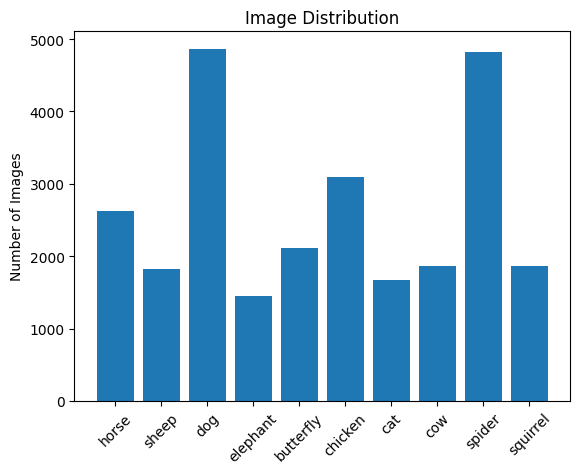

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
image_count = []

for folder in os.listdir(images_path):
  #count number of images in each folder
  folder_path = os.path.join(images_path, folder)
  num_images = len(os.listdir(folder_path))

  image_count.append((folder, num_images))

dist_df = pd.DataFrame(image_count, columns=['Folder', 'Count'])

plt.bar(dist_df['Folder'], dist_df['Count'])
plt.title('Image Distribution')
plt.ylabel('Number of Images')
plt.xticks(rotation=45)

plt.savefig('image_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

#files.download('image_distribution.png')

Look at image dimensions in the dog folder

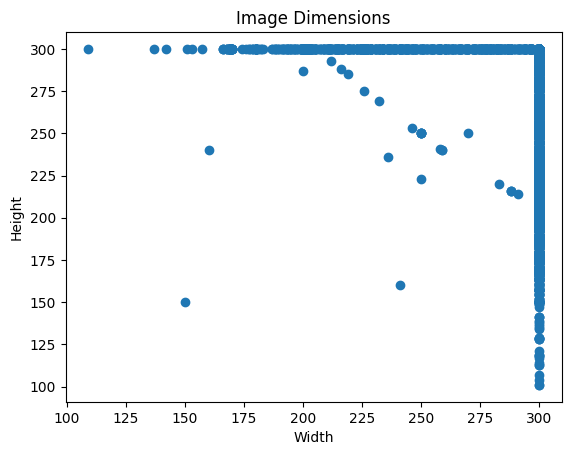

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
folder_path = os.path.join(images_path, 'dog')

image_dimensions = []

for file in os.listdir(folder_path):
    image_path = os.path.join(folder_path, file)

    with Image.open(image_path) as img:
        width, height = img.size

    image_dimensions.append((file, width, height))

dim_df = pd.DataFrame(image_dimensions, columns=['File', 'Width', 'Height'])

plt.scatter(dim_df['Width'], dim_df['Height'])
plt.title('Image Dimensions')
plt.xlabel('Width')
plt.ylabel('Height')

plt.savefig('image_size_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

files.download('image_size_distribution.png')

Check for corrupt images

In [ ]:
for folder in os.listdir(images_path):
  folder_path = os.path.join(images_path, folder)

  for file in os.listdir(folder_path):
        image_path = os.path.join(folder_path, file)

        try: #use this because we know there may be errors
            with Image.open(image_path) as img:
                img.verify()
        except Exception:
            print("Corrupted image:", image_path)

Check how many images have different color formats

In [ ]:
color_counts = {}

for folder in os.listdir(images_path):
    folder_path = os.path.join(images_path, folder)

    for file in os.listdir(folder_path):
        image_path = os.path.join(folder_path, file)

        with Image.open(image_path) as img:
            mode = img.mode
            color_counts[mode] = color_counts.get(mode, 0) + 1

print(color_counts)


#delete the images that are not RGB
for folder in os.listdir(images_path):
    folder_path = os.path.join(images_path, folder)

    for file in os.listdir(folder_path):
        image_path = os.path.join(folder_path, file)

        with Image.open(image_path) as img:
            if img.mode != "RGB":
                print("Non-RGB:", image_path)
                #os.remove(image_path)

{'RGB': 26128, 'RGBA': 49, 'CMYK': 1, 'L': 1}
Non-RGB: /content/drive/MyDrive/animals10/raw-img/elephant/ea35b80a2df1033ed1584d05fb1d4e9fe777ead218ac104497f5c978a4efb4bb_640.png
Non-RGB: /content/drive/MyDrive/animals10/raw-img/elephant/ea35b80a2df1053ed1584d05fb1d4e9fe777ead218ac104497f5c978a4efb4bb_640.png
Non-RGB: /content/drive/MyDrive/animals10/raw-img/elephant/ea34b10b21f5083ed1584d05fb1d4e9fe777ead218ac104497f5c978a4efb4bb_640.jpg
Non-RGB: /content/drive/MyDrive/animals10/raw-img/elephant/e835b50620f7083ed1584d05fb1d4e9fe777ead218ac104497f5c978a4eebdbd_640.png
Non-RGB: /content/drive/MyDrive/animals10/raw-img/elephant/ea35b80a2df1043ed1584d05fb1d4e9fe777ead218ac104497f5c978a4efb4bb_640.png
Non-RGB: /content/drive/MyDrive/animals10/raw-img/elephant/e83db7072afd013ed1584d05fb1d4e9fe777ead218ac104497f5c978a4eebdbd_640.jpg
Non-RGB: /content/drive/MyDrive/animals10/raw-img/elephant/e835b50620f7093ed1584d05fb1d4e9fe777ead218ac104497f5c978a4eebdbd_640.png
Non-RGB: /content/drive/MyDriv

### Note to self: Run this every time I reopen my code

Load images and labels. Resize images by changing the pixel dimensions to 128x128 (may adjust later). Divide into training and test sets.

In [4]:
images = []
labels = []

folders = sorted(os.listdir(images_path))

for label, folder in enumerate(folders):
    folder_path = os.path.join(images_path, folder)

    for file in os.listdir(folder_path):
        image_path = os.path.join(folder_path, file)

        with Image.open(image_path) as img:
            img = img.resize((128, 128)) #may change this later
            images.append(np.array(img))

        labels.append(label)

#Convert to numpy arrays immediately after loading
images = np.array(images)
labels = np.array(labels)

#Divide the data into training and test sets
x_train, x_test, y_train, y_test = train_test_split(
    images,
    labels,
    test_size=0.2,
    random_state=1,
    stratify=labels
    #stratify keeps the same proportion of training and test images
    #within each label
)

#scale the images from 0-255 to 0-1
x_train, x_test = x_train / 255.0, x_test / 255.0

#one hot encode the categories
num_classes = 10
y_train = tf.keras.utils.to_categorical(y_train, num_classes)
y_test  = tf.keras.utils.to_categorical(y_test , num_classes)

# First Model - Simple CNN

Build an initial simple CNN

In [ ]:
model = models.Sequential([

    layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(128,128,3)),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.Flatten(),

    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

model.summary()

Compile and train model
Calculate test accuracy, and predict on unseen images

In [ ]:
#compile and train model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train, y_train,
                    epochs=15,
                    batch_size=64,
                    validation_split=0.2,
                    verbose=2)

#calculate test accuracy, and predict on unseen images
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)

print(f"Test accuracy = {test_acc:.3f}")

predictions = model.predict(x_test)

plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.show()

NameError: name 'model' is not defined

# Simple CNN Hyperparameter Tuning

Find an alternative to flatten. Try max pooling instead.

In [5]:
model = models.Sequential([

    layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(128,128,3)),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu', padding='same'),

    GlobalMaxPooling2D(), #removed flatten, replaced it with this

    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling2d            │ (None, 64)             │             0 │
│ (GlobalMaxPooling2D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,130 (238.79 KB)

 Trainable params: 61,130 (238.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
262/262 - 29s - 111ms/step - accuracy: 0.2831 - loss: 2.0237 - val_accuracy: 0.3896 - val_loss: 1.7761
Epoch 2/15
262/262 - 7s - 26ms/step - accuracy: 0.4223 - loss: 1.6808 - val_accuracy: 0.4597 - val_loss: 1.5626
Epoch 3/15
262/262 - 7s - 26ms/step - accuracy: 0.4833 - loss: 1.5062 - val_accuracy: 0.4772 - val_loss: 1.4905
Epoch 4/15
262/262 - 7s - 26ms/step - accuracy: 0.5223 - loss: 1.3944 - val_accuracy: 0.5152 - val_loss: 1.4198
Epoch 5/15
262/262 - 7s - 26ms/step - accuracy: 0.5466 - loss: 1.3108 - val_accuracy: 0.5475 - val_loss: 1.3316
Epoch 6/15
262/262 - 7s - 26ms/step - accuracy: 0.5717 - loss: 1.2412 - val_accuracy: 0.5621 - val_loss: 1.2566
Epoch 7/15
262/262 - 7s - 26ms/step - accuracy: 0.5931 - loss: 1.1851 - val_accuracy: 0.5745 - val_loss: 1.2374
Epoch 8/15
262/262 - 7s - 26ms/step - accuracy: 0.6090 - loss: 1.1430 - val_accuracy: 0.5903 - val_loss: 1.2091
Epoch 9/15
262/262 - 7s - 26ms/step - accuracy: 0.6256 - loss: 1.0885 - val_accuracy: 0.5996 - val_los

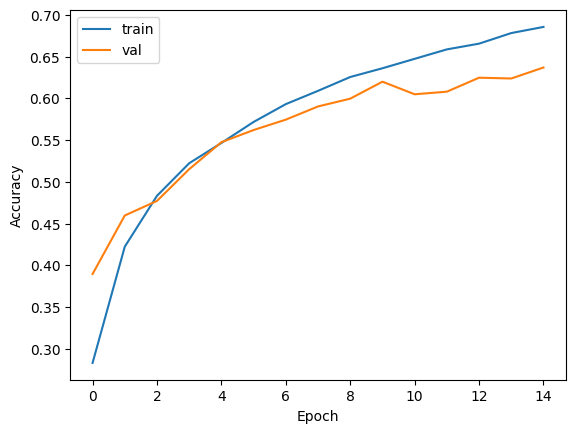

In [6]:
#compile and train model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train, y_train,
                    epochs=15,
                    batch_size=64,
                    validation_split=0.2,
                    verbose=2)

#calculate test accuracy, and predict on unseen images
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)

print(f"Test accuracy = {test_acc:.3f}")

predictions = model.predict(x_test)

plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.show()